<a href="https://colab.research.google.com/github/sangetha959764-ship-it/MINI-PROJECT-3/blob/main/MINI_PROJECT_3_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LOAD DATASET

In [ ]:
import pandas as pd
df = pd.read_csv('/content/HR_Job_Placement_Dataset (1).csv')
df

,age_years,gender,ssc_percentage,hsc_percentage,degree_percentage,degree_specialization,technical_score,aptitude_score,communication_score,skills_match_percentage,...,expected_ctc_lpa,company_tier,job_role_match,competition_level,bond_requirement,notice_period_days,layoff_history,employment_gap_months,relocation_willingness,status
0,27,Male,65.061656,83.842578,75.856526,Computer Science,58.221909,89.566305,64.474484,79.548913,...,5.805850,Tier 3,Not Matched,Medium,Not Required,15.0,No,18.0,Not Willing,Not Placed
1,24,Male,67.885626,64.973305,73.093588,Electronics,71.927978,54.591971,61.077306,73.316134,...,10.807739,Tier 1,Matched,High,Required,0.0,NaN,NaN,Not Willing,Not Placed
2,33,Female,73.892471,68.834121,90.196460,Information Technology,72.445041,58.587088,79.494739,75.466980,...,5.476839,Tier 3,Not Matched,Low,Not Required,0.0,No,3.0,Not Willing,Placed
3,31,Male,74.145568,76.255126,75.586731,Mechanical,78.855676,61.022065,53.740386,73.676449,...,9.980580,Tier 2,Matched,Low,Not Required,0.0,Yes,6.0,NaN,Not Placed
4,28,Male,60.475937,65.786336,80.801010,Information Technology,68.286776,65.713731,61.438314,88.994847,...,8.921233,Tier 2,Matched,Medium,Not Required,0.0,No,3.0,Willing,Not Placed
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51495,24,Female,65.747180,72.063946,72.247881,Electronics,55.923057,73.208032,69.108895,63.992488,...,6.315211,Tier 1,Matched,Low,Required,0.0,No,3.0,NaN,Not Placed
51496,22,Male,61.921459,66.729203,55.000000,Others,69.525121,70.245612,54.959868,88.514232,...,8.655391,Tier 1,Matched,Medium,Not Required,60.0,No,0.0,Not Willing,Placed
51497,30,Male,75.578202,75.717623,75.048301,Information Technology,73.073239,58.870416,71.219454,79.326789,...,11.538547,Tier 1,Matched,High,Not Required,0.0,No,12.0,NaN,Placed
51498,29,Female,77.327209,56.629227,69.735374,Mechanical,48.270078,61.171900,71.650243,76.318681,...,9.617279,Tier 2,Matched,Medium,Not Required,0.0,Yes,0.0,Willing,Not Placed


In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51500 entries, 0 to 51499
Data columns (total 26 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   age_years                  51500 non-null  int64  
 1   gender                     51500 non-null  object 
 2   ssc_percentage             48919 non-null  float64
 3   hsc_percentage             49435 non-null  float64
 4   degree_percentage          51500 non-null  float64
 5   degree_specialization      51500 non-null  object 
 6   technical_score            51500 non-null  float64
 7   aptitude_score             51500 non-null  float64
 8   communication_score        51500 non-null  float64
 9   skills_match_percentage    51500 non-null  float64
 10  certifications_count       51500 non-null  int64  
 11  internship_experience      51500 non-null  object 
 12  years_of_experience        51500 non-null  int64  
 13  career_switch_willingness  43034 non-null  obj

In [ ]:
print(df.isnull().sum())

age_years                       0
gender                          0
ssc_percentage               2581
hsc_percentage               2065
degree_percentage               0
degree_specialization           0
technical_score                 0
aptitude_score                  0
communication_score             0
skills_match_percentage         0
certifications_count            0
internship_experience           0
years_of_experience             0
career_switch_willingness    8466
relevant_experience          8426
previous_ctc_lpa                0
expected_ctc_lpa                0
company_tier                    0
job_role_match               6131
competition_level               0
bond_requirement                0
notice_period_days           1582
layoff_history               8467
employment_gap_months        1097
relocation_willingness       8475
status                          0
dtype: int64


In [ ]:
print(df.duplicated().sum())

1376


# DATA CLEANING

In [ ]:
df = df.drop_duplicates()
print('after drop duplicate values:', df.shape)

after drop duplicate values: (50124, 26)


# HANDLE MISSING VALUES

NUMERICAL COLUMN

In [ ]:
num_cols = df.select_dtypes(include=['int64', 'float64']).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

/tmp/ipykernel_857/2748600121.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[col] = df[col].fillna(df[col].median())


CATEGORICAL COLUMN

In [ ]:
cat_cols = df.select_dtypes(include=['object']).columns

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

/tmp/ipykernel_857/3477175695.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[col] = df[col].fillna(df[col].mode()[0])


In [ ]:
print(df.isnull().sum())

age_years                    0
gender                       0
ssc_percentage               0
hsc_percentage               0
degree_percentage            0
degree_specialization        0
technical_score              0
aptitude_score               0
communication_score          0
skills_match_percentage      0
certifications_count         0
internship_experience        0
years_of_experience          0
career_switch_willingness    0
relevant_experience          0
previous_ctc_lpa             0
expected_ctc_lpa             0
company_tier                 0
job_role_match               0
competition_level            0
bond_requirement             0
notice_period_days           0
layoff_history               0
employment_gap_months        0
relocation_willingness       0
status                       0
dtype: int64


**Correcting inconsistent categorical label**

In [ ]:
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip().str.title()



/tmp/ipykernel_857/1188313207.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[col] = df[col].str.strip().str.title()


**Encoding categorical variables ( One-Hot Encoding)**


In [ ]:
encoded_gender = pd.get_dummies(df['gender'],dtype=int)
print(encoded_gender.head())

   Female  Male
0       0     1
1       0     1
2       1     0
3       0     1
4       0     1


Feature scaling for numerical columns

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaled_data = scaler.fit_transform(df[['age_years', 'technical_score', 'aptitude_score', 'communication_score']])

print(scaled_data[:5])

[[-0.12559396 -0.82774412  2.57927079 -0.16437138]
 [-0.87062588  0.32819043 -0.94822634 -0.50745605]
 [ 1.36446989  0.37179814 -0.5452805   1.35254014]
 [ 0.86778194  0.91245462 -0.29968967 -1.24841944]
 [ 0.12275002  0.02110085  0.17350984 -0.47099747]]


**Ensuring logical consistency across features**

In [ ]:
print("Invalid Age:",
      (df['age_years'] <= 0).sum())

print("Invalid Experience:",
      (df['years_of_experience'] < 0).sum())

print("Invalid SSC Percentage:",
      ((df['ssc_percentage'] < 0) |
       (df['ssc_percentage'] > 100)).sum())

print("Invalid HSC Percentage:",
      ((df['hsc_percentage'] < 0) |
       (df['hsc_percentage'] > 100)).sum())

print("Invalid Degree Percentage:",
      ((df['degree_percentage'] < 0) |
       (df['degree_percentage'] > 100)).sum())

Invalid Age: 0
Invalid Experience: 0
Invalid SSC Percentage: 0
Invalid HSC Percentage: 0
Invalid Degree Percentage: 0


# EDA ( EXPLORATORY DATA ANALYSIS)

**1 . Interview score vs job acceptance
**

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

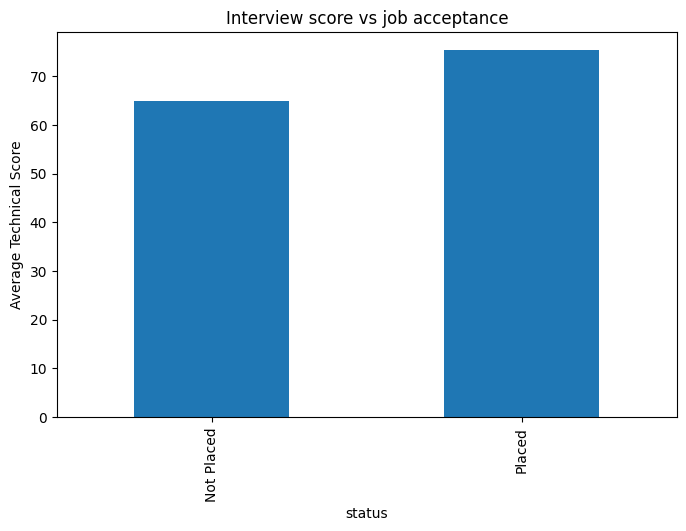

In [ ]:
avg_score = df.groupby('status')['technical_score'].mean()

plt.figure(figsize=(8,5))
avg_score.plot(kind='bar')

plt.title('Interview score vs job acceptance')
plt.xlabel('status')
plt.ylabel('Average Technical Score')

plt.show()



1.   Placed candidates have a higher average technical score compared to not-placed candidates.
2. Technical score plays an important role in candidate selection.
3. Candidates with better technical performance have a higher chance of getting placed.






**2. Skills match percentage impact on placement
**

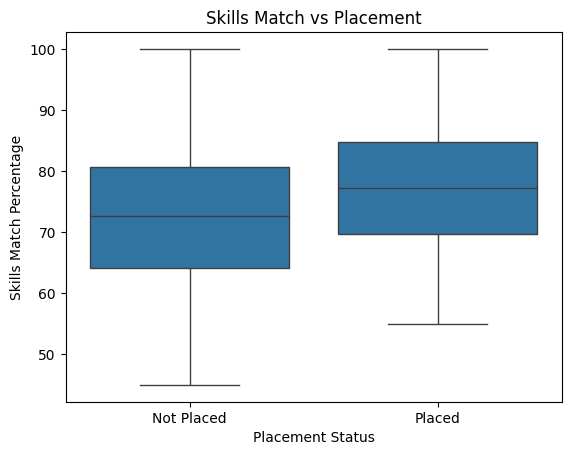

In [ ]:
sns.boxplot(
    x='status',
    y='skills_match_percentage',
    data=df)

plt.title('Skills Match vs Placement')
plt.xlabel('Placement Status')
plt.ylabel('Skills Match Percentage')
plt.show()

1. Placed candidates generally have higher skills match percentages.
2. Candidates with better skill matching have a higher chance of getting placed.
3. Skills match percentage is an important factor in job placement.

**3. Company tier vs acceptance rate
**

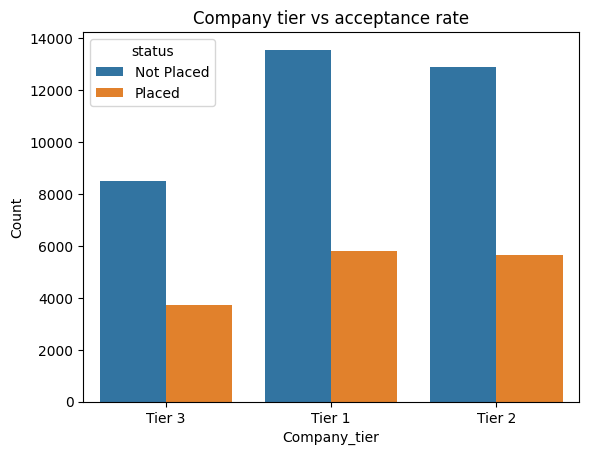

In [ ]:
sns.countplot(x='company_tier', hue = 'status',data=df)
plt.xlabel('Company_tier')
plt.ylabel('Count')
plt.title('Company tier vs acceptance rate')
plt.show()

 1. Candidates are distributed across Tier 1, Tier 2, and Tier 3 companies.
 2. The number of placed and not-placed candidates varies across company tiers.
 3. Company tier may influence placement opportunities.
4. Candidates applying to different company tiers have different placement outcomes.

** 4. Experience vs placement probability
**

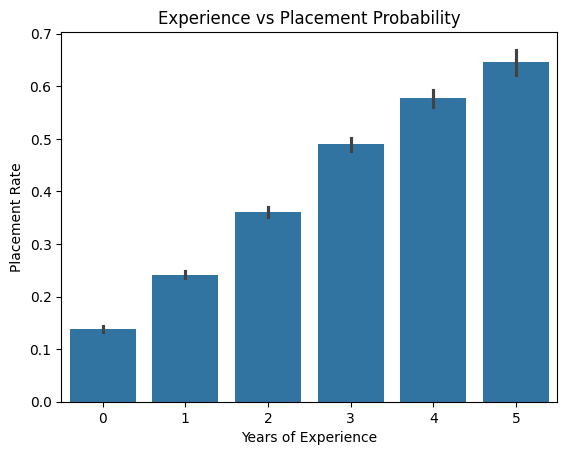

In [ ]:
sns.barplot(
    x='years_of_experience',
    y=df['status'].eq('Placed').astype(int),
    data=df)

plt.title('Experience vs Placement Probability')
plt.xlabel('Years of Experience')
plt.ylabel('Placement Rate')
plt.show()

 1. Placement rate varies based on years of experience.
 2. Candidates with relevant work experience may have better placement opportunities.
 3. Experience can be an important factor in candidate selection.
4. Freshers may also get placed depending on their skills and performance.

** 5. Competition level vs job acceptance
**

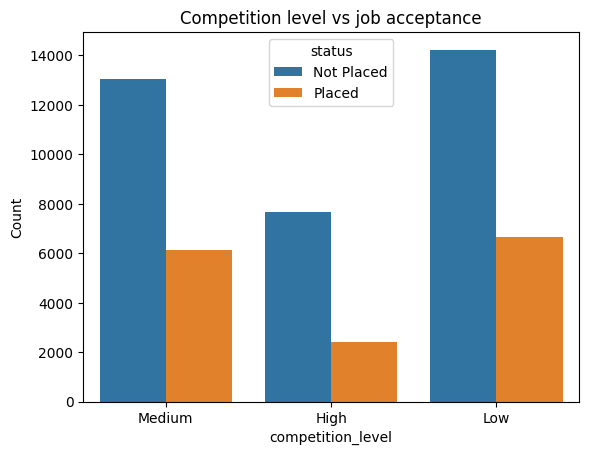

In [ ]:
sns.countplot(x='competition_level', hue = 'status',data=df)
plt.xlabel('competition_level')
plt.ylabel('Count')
plt.title('Competition level vs job acceptance')
plt.show()

 1. Candidates face different levels of competition during the placement process.
 2. The number of placed and not-placed candidates varies across competition levels.
 3. Higher competition may reduce placement opportunities.
4. Competition level can influence candidate placement outcomes.

** 6. Correlation analysis among numeric features
**

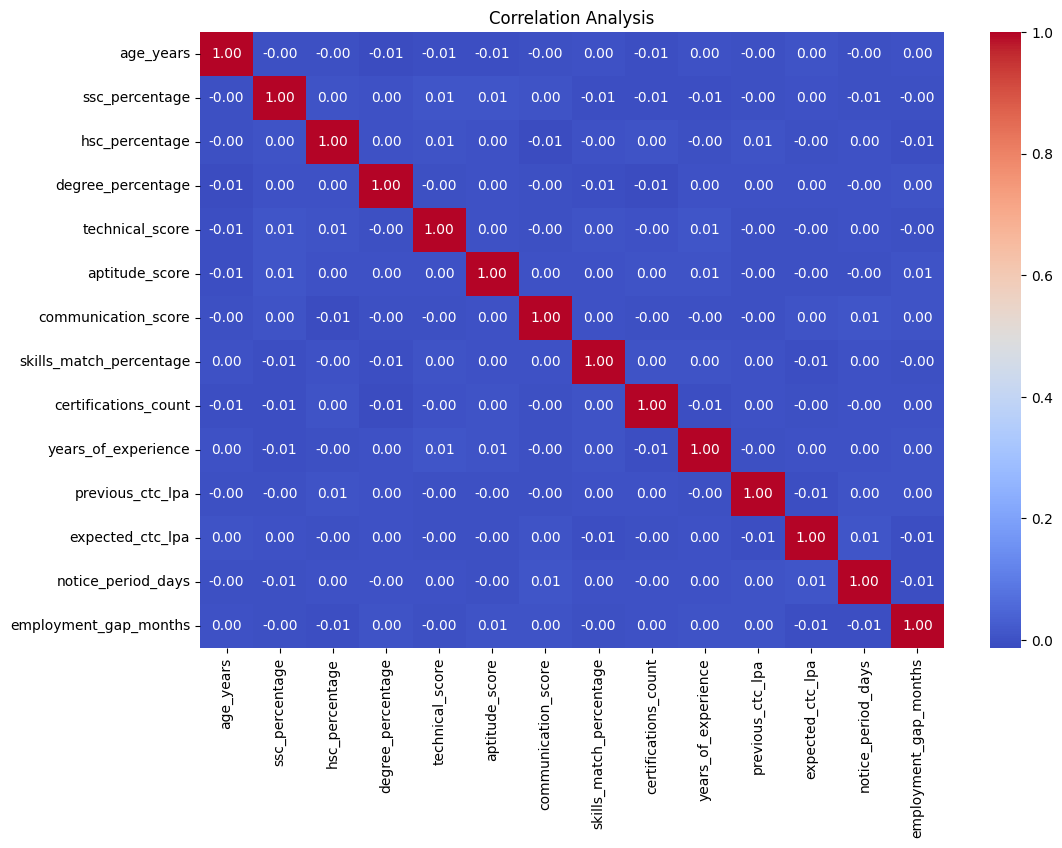

In [ ]:
numeric_df = df.select_dtypes(include='number')

plt.figure(figsize=(12,8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f')

plt.title('Correlation Analysis')
plt.show()

 1. Correlation analysis helps identify relationships between numerical features.
 2. Positive correlation means two variables increase together.
 3. Negative correlation means one variable increases while the other decreases.
 4. Strong correlation indicates a closer relationship between two variables.
5. Technical score, skills match, and academic performance may have relationships with placement statu

# Feature enginnering

** 1. Experience category (Fresher / Junior / Senior)
**

In [ ]:
def experience_category(x):
    if x <= 2:
        return 'Fresher'
    elif x <= 4:
        return 'Junior'
    else:
        return 'Senior'

df['experience_category'] = df['years_of_experience'].apply(experience_category)

/tmp/ipykernel_857/766748365.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['experience_category'] = df['years_of_experience'].apply(experience_category)


**2. Academic performance bands**

In [ ]:
def academic_band(x):
    if x < 60:
        return 'Low'
    elif x < 75:
        return 'Average'
    elif x < 85:
        return 'Good'
    else:
        return 'Excellent'

df['academic_band'] = df['degree_percentage'].apply(academic_band)

/tmp/ipykernel_857/1373405293.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['academic_band'] = df['degree_percentage'].apply(academic_band)


**3. Skills match level (Low / Medium / High)
**

In [ ]:
def skill_level(x):
    if x < 50:
        return 'Low'
    elif x < 75:
        return 'Medium'
    else:
        return 'High'

df['skill_level'] = df['skills_match_percentage'].apply(skill_level)

/tmp/ipykernel_857/3676849591.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['skill_level'] = df['skills_match_percentage'].apply(skill_level)


** 4. Interview performance category
**

In [ ]:
interview_score = (
    df['technical_score'] +
    df['aptitude_score'] +
    df['communication_score']) / 3

def interview_category(x):
    if x < 50:
        return 'Low'
    elif x < 75:
        return 'Medium'
    else:
        return 'High'

df['interview_performance_category'] = interview_score.apply(interview_category)

/tmp/ipykernel_857/1211114279.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['interview_performance_category'] = interview_score.apply(interview_category)


** 5. Placement probability score**

In [ ]:
df['placement_probability_score'] = (
    df['degree_percentage'] +
    df['skills_match_percentage'] +
    df['technical_score'] +
    df['aptitude_score'] +
    df['communication_score']
) / 5

/tmp/ipykernel_857/105150672.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['placement_probability_score'] = (


In [ ]:
print("Dataset Shape:", df.shape)

df[['experience_category',
    'academic_band',
    'skill_level',
    'interview_performance_category',
    'placement_probability_score']].head()

Dataset Shape: (50124, 31)


,experience_category,academic_band,skill_level,interview_performance_category,placement_probability_score
0,Fresher,Good,High,Medium,73.533627
1,Fresher,Average,Medium,Medium,66.801395
2,Fresher,Excellent,High,Medium,75.238061
3,Fresher,Good,Medium,Medium,68.576261
4,Fresher,Good,High,Medium,73.046936


# machine learning

In [ ]:
print(df['status'].value_counts())

status
Not Placed    34950
Placed        15174
Name: count, dtype: int64


In [ ]:
df['status'] = df['status'].map({
    'Not Placed': 0,
    'Placed': 1
})

print(df['status'].value_counts())

status
0    34950
1    15174
Name: count, dtype: int64


/tmp/ipykernel_857/4026362782.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['status'] = df['status'].map({




  X = Input features (independent variables)
y = Target column (dependent variable)


In [ ]:
X = df.drop('status', axis=1)
y = df['status']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (50124, 30)
y shape: (50124,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(   X, y, test_size=0.2,random_state=42, stratify=y)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (40099, 30)
X_test: (10025, 30)
y_train: (40099,)
y_test: (10025,)


In [ ]:
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns

cat_cols = X_train.select_dtypes(include=['object', 'category']).columns

print("Numerical columns:", list(num_cols))
print("Categorical columns:", list(cat_cols))

Numerical columns: ['age_years', 'ssc_percentage', 'hsc_percentage', 'degree_percentage', 'technical_score', 'aptitude_score', 'communication_score', 'skills_match_percentage', 'certifications_count', 'years_of_experience', 'previous_ctc_lpa', 'expected_ctc_lpa', 'notice_period_days', 'employment_gap_months', 'placement_probability_score']
Categorical columns: ['gender', 'degree_specialization', 'internship_experience', 'career_switch_willingness', 'relevant_experience', 'company_tier', 'job_role_match', 'competition_level', 'bond_requirement', 'layoff_history', 'relocation_willingness', 'experience_category', 'academic_band', 'skill_level', 'interview_performance_category']


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)])

# Fit on training data and transform
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_processed = preprocessor.transform(X_test)

print("Training data after preprocessing:", X_train_processed.shape)
print("Testing data after preprocessing:", X_test_processed.shape)

Training data after preprocessing: (40099, 55)
Testing data after preprocessing: (10025, 55)


**Logistic Regression**

In [ ]:
from sklearn.linear_model import LogisticRegression


model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_processed, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


**Make predictions - 1**

In [ ]:
y_pred = model.predict(X_test_processed)

print("Predictions:", y_pred[:10])

Predictions: [0 1 0 1 0 0 0 0 1 0]


**: Calculate evaluation metric**

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 87.05236907730674 %

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.92      0.91      6990
           1       0.80      0.76      0.78      3035

    accuracy                           0.87     10025
   macro avg       0.85      0.84      0.84     10025
weighted avg       0.87      0.87      0.87     10025



**Confusion Matrix**

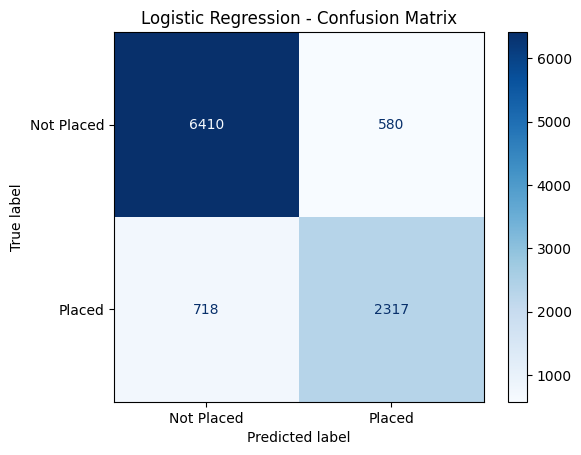

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Not Placed', 'Placed']
)

display.plot(cmap='Blues')
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

Random Forest Model

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
)

rf_model.fit(X_train_processed, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [ ]:
print("X_train shape:", X_train.shape)
print("Text columns:")
print(X_train.select_dtypes(include='object').columns.tolist())

X_train shape: (40099, 30)
Text columns:
['gender', 'degree_specialization', 'internship_experience', 'career_switch_willingness', 'relevant_experience', 'company_tier', 'job_role_match', 'competition_level', 'bond_requirement', 'layoff_history', 'relocation_willingness', 'experience_category', 'academic_band', 'skill_level', 'interview_performance_category']


In [ ]:
print(X_train.head())

       age_years  gender  ssc_percentage  hsc_percentage  degree_percentage  \
43124         21    Male       50.000000       60.589040          73.018035   
26110         32    Male       69.935716       73.298243          61.411902   
11576         21    Male       66.534135       76.080461          78.108183   
45273         32    Male       59.729692       75.592319          79.552148   
32035         23  Female       70.777605       81.450304          69.872572   

      degree_specialization  technical_score  aptitude_score  \
43124            Mechanical        59.254504       60.696263   
26110                Others        58.110485       47.505329   
11576            Mechanical        50.782648       69.135172   
45273                Others        71.197427       55.682774   
32035                Others        88.574328       62.360267   

       communication_score  skills_match_percentage  ...  bond_requirement  \
43124            63.605278                72.294333  ...      

Encode the Random Forest data*

In [ ]:
import pandas as pd

X_train_rf = pd.get_dummies(X_train, drop_first=True)
X_test_rf = pd.get_dummies(X_test, drop_first=True)


X_train_rf, X_test_rf = X_train_rf.align(
    X_test_rf,
    join='left',
    axis=1,
    fill_value=0)

print("Train shape:", X_train_rf.shape)
print("Test shape:", X_test_rf.shape)
print("Remaining text columns:",
      X_train_rf.select_dtypes(include='object').columns.tolist())

Train shape: (40099, 40)
Test shape: (10025, 40)
Remaining text columns: []


Train Random Forest model

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42)

rf_model.fit(X_train_rf, y_train)

print("Random Forest training completed!")

Random Forest training completed!


Predict and evaluate

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

y_pred_rf = rf_model.predict(X_test_rf)

print("Random Forest Accuracy:",
      accuracy_score(y_test, y_pred_rf) * 100)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 88.41895261845386

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.94      0.92      6990
           1       0.85      0.75      0.80      3035

    accuracy                           0.88     10025
   macro avg       0.87      0.85      0.86     10025
weighted avg       0.88      0.88      0.88     10025



Final Model Selection:

Conclusion:

Both Logistic Regression (87.05) and Random Forest algorithms were evaluated for candidate placement prediction. After comparing their performance metrics, Random Forest was selected as the final model because it achieved 88.42% accuracy and showed good classification performance.

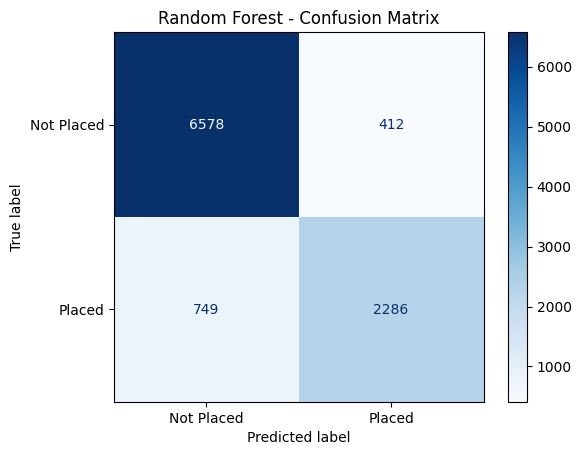

Confusion Matrix:
[[6578  412]
 [ 749 2286]]


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Predictions
y_pred_rf = rf_model.predict(X_test_rf)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_rf)

# Display
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Not Placed', 'Placed']
)

disp.plot(cmap='Blues')
plt.title("Random Forest - Confusion Matrix")
plt.show()

print("Confusion Matrix:")
print(cm)

feature importance

                        Feature  Importance
4               technical_score    0.188431
14  placement_probability_score    0.100702
9           years_of_experience    0.081492
11             expected_ctc_lpa    0.063651
7       skills_match_percentage    0.059254
10             previous_ctc_lpa    0.045843
6           communication_score    0.038840
25   job_role_match_Not Matched    0.036246
5                aptitude_score    0.035193
3             degree_percentage    0.034627
31   experience_category_Junior    0.034272
1                ssc_percentage    0.031635
2                hsc_percentage    0.031558
20    internship_experience_Yes    0.023658
0                     age_years    0.021791


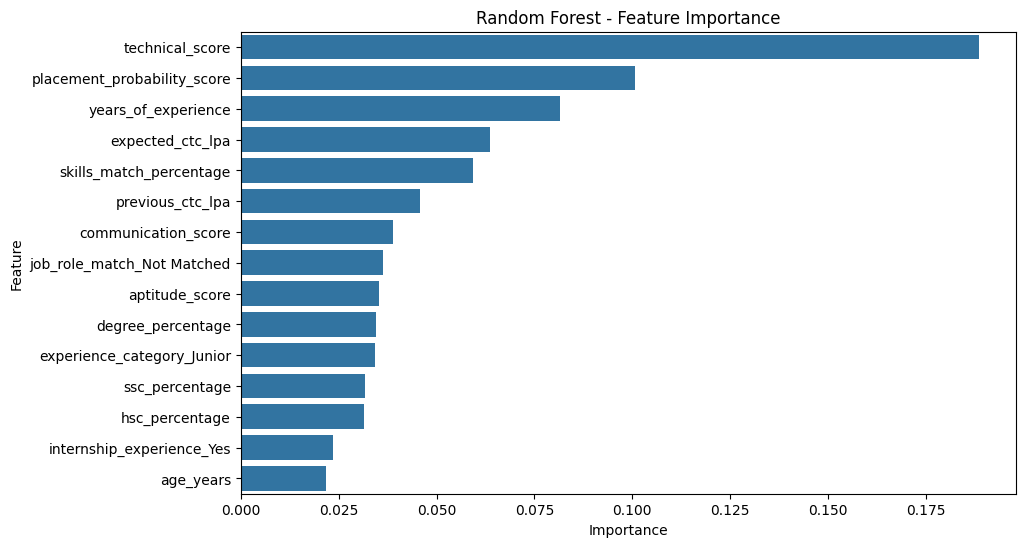

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Feature Importance
feature_importance = pd.DataFrame({
    'Feature': X_train_rf.columns,
    'Importance': rf_model.feature_importances_
})

# Sort values
feature_importance = feature_importance.sort_values(
    by='Importance', ascending=False
)

# Display top 15 features
print(feature_importance.head(15))

# Plot graph
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(15),
    x='Importance',
    y='Feature'
)

plt.title("Random Forest - Feature Importance")
plt.show()

 Save Random Forest Model

Reason:
* We don't need to train the model again every time.
 * We can reuse the trained model for future predictions.
* We can integrate the saved model into our Streamlit application.
 * It saves time and makes deployment easier.





In [ ]:
import pickle

# Save Random Forest model
with open('random_forest_model.pkl', 'wb') as file:
    pickle.dump(rf_model, file)

print("Random Forest Model Saved Successfully!")

Random Forest Model Saved Successfully!


In [ ]:
with open('feature_columns.pkl', 'wb') as file:
    pickle.dump(X_train_rf.columns.tolist(), file)

print("Feature Columns Saved Successfully!")

Feature Columns Saved Successfully!


In [ ]:
from google.colab import files

files.download('random_forest_model.pkl')
files.download('feature_columns.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# cleaned dataset

In [ ]:
data_file = ' clean_HR_job_placement_dataset.csv'
df.to_csv(data_file, index=False)

In [ ]:
cleaned_data = pd.read_csv('/content/ clean_HR_job_placement_dataset.csv')
print(cleaned_data.head())

   age_years  gender  ssc_percentage  hsc_percentage  degree_percentage  \
0         27    Male       65.061656       83.842578          75.856526   
1         24    Male       67.885626       64.973305          73.093588   
2         33  Female       73.892471       68.834121          90.196460   
3         31    Male       74.145568       76.255126          75.586731   
4         28    Male       60.475937       65.786336          80.801010   

    degree_specialization  technical_score  aptitude_score  \
0        Computer Science        58.221909       89.566305   
1             Electronics        71.927978       54.591971   
2  Information Technology        72.445041       58.587088   
3              Mechanical        78.855676       61.022065   
4  Information Technology        68.286776       65.713731   

   communication_score  skills_match_percentage  ...  notice_period_days  \
0            64.474484                79.548913  ...                15.0   
1            61.077306  

In [ ]:
from google.colab import files

df.to_csv('placement_cleaned_data.csv', index=False)

files.download('placement_cleaned_data.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>